# Project: Recreate Graphs using Matplotlib
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data - lesson 2 project*

A high school math teacher wants to see patterns in their classes' results. Codecademy shows a finished chart for each task; the job is to rebuild it from scratch with the plot types from [02_different_plot_types](02_different_plot_types.ipynb).

Every chart is saved to `charts/` and collected in this folder's [README](README.md).

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'

## Data
All the data for the project in one place - test results of the teacher's classes, as given by Codecademy. Each task below uses these lists.

In [2]:
# task 1 - final exam averages per year, with error
past_years_averages = [82, 84, 83, 86, 74, 84, 90]
years = [2000, 2001, 2002, 2003, 2004, 2005, 2006]
error = [1.5, 2.1, 1.2, 3.2, 2.3, 1.7, 2.4]

# task 2 - test averages per unit, by middle school the students came from
unit_topics = ['Limits', 'Derivatives', 'Integrals', 'Diff Eq', 'Applications']
middle_school_a = [80, 85, 84, 83, 86]
middle_school_b = [73, 78, 77, 82, 86]

## 1. Bar Chart with Error
**Task:** final exam averages for 2000-2006 as bars with error bars (cap size 5), figure 10 x 8, axis from -0.5 to 6.5 (x) and 70 to 95 (y), years as tick labels, title and axis labels.

My code:

```python
plt.figure(figsize=(10, 8))
plt.bar(range(len(past_years_averages)),past_years_averages,capsize=5, yerr=error)
plt.axis([-0.5,6.5,70,95])
ax = plt.subplot()
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)
plt.xlabel("Year")
plt.ylabel("Test average")
plt.title("Final Exam Averages")
plt.show()

plt.savefig("my_bar_chart.png")
```

**Mistake: `savefig` after `show` - the saved file is blank.** `plt.show()` displays the figure and then clears it, so `savefig` saves an empty sheet. Codecademy may still pass it, but locally the PNG comes out white. **Save, then show.**

Fixed:

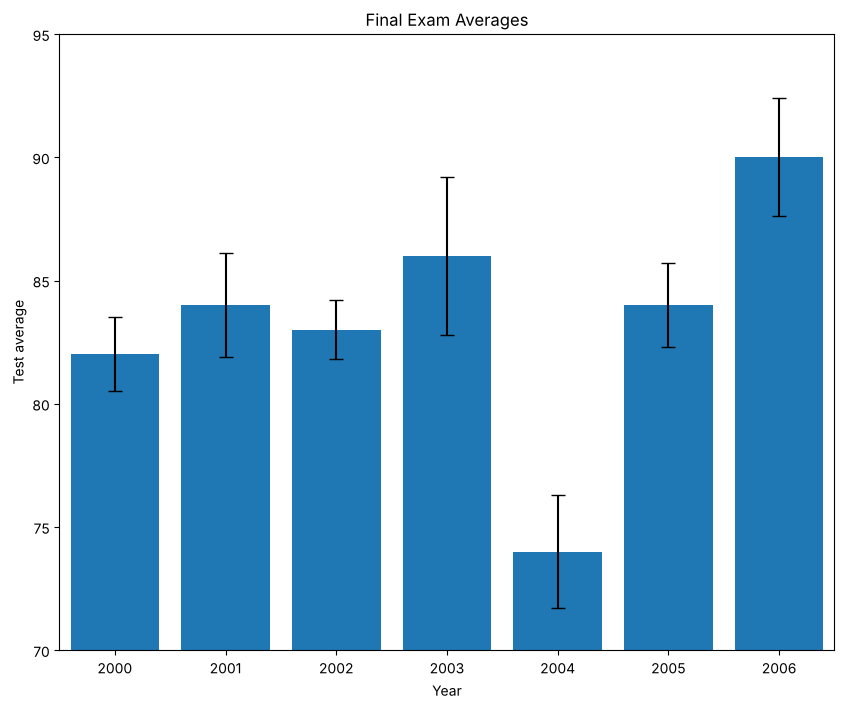

In [3]:
plt.figure(figsize=(10, 8))
plt.bar(range(len(past_years_averages)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 70, 95])

ax = plt.subplot()
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years)

plt.title("Final Exam Averages")
plt.xlabel("Year")
plt.ylabel("Test average")

plt.savefig(CHARTS + 'recreate_01_bar_chart_error.png')   # save first
plt.show()                                                # then show

**Truncated axis:** the task makes the y-axis start at **70** - against the rule from [section 1 of the lesson](02_different_plot_types.ipynb) that bars start at 0. A bar's height *is* its value, so with the axis cut off 2004 (74) looks like a collapse and 2006 (90) like a huge jump - the real spread is 74 to 90 out of 100. Same data, honest axis:

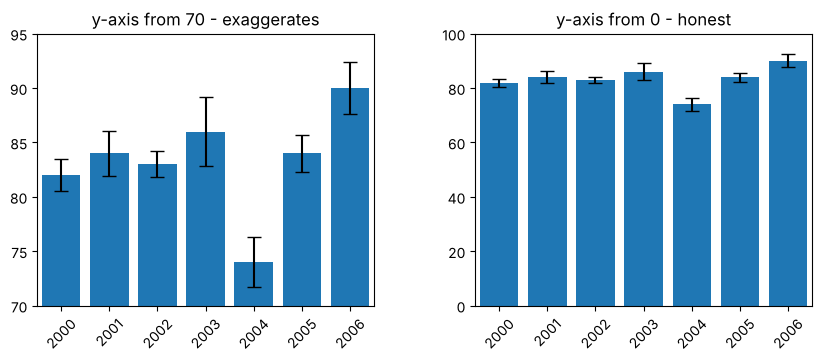

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(range(len(years)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 70, 95])
plt.xticks(range(len(years)), years, rotation=45)
plt.title('y-axis from 70 - exaggerates')

plt.subplot(1, 2, 2)
plt.bar(range(len(years)), past_years_averages, yerr=error, capsize=5)
plt.axis([-0.5, 6.5, 0, 100])
plt.xticks(range(len(years)), years, rotation=45)
plt.title('y-axis from 0 - honest')

plt.subplots_adjust(wspace=0.3, bottom=0.2)
plt.savefig(CHARTS + 'recreate_01b_truncated_vs_honest.png')
plt.show()

- Style: a space after each comma - `past_years_averages, capsize=5`. Runs either way, but it's the convention.
- If the zoom is really needed, use dots or a line with error bars instead of bars - a dot's position doesn't pretend to be a quantity starting at 0.

## 2. Side By Side Bars
**Task:** average test scores per unit for students from Middle School A and B, side by side - x positions with `create_x`, ticks in the middle of each pair, unit names as labels, legend, title and axis labels, figure 10 x 8.

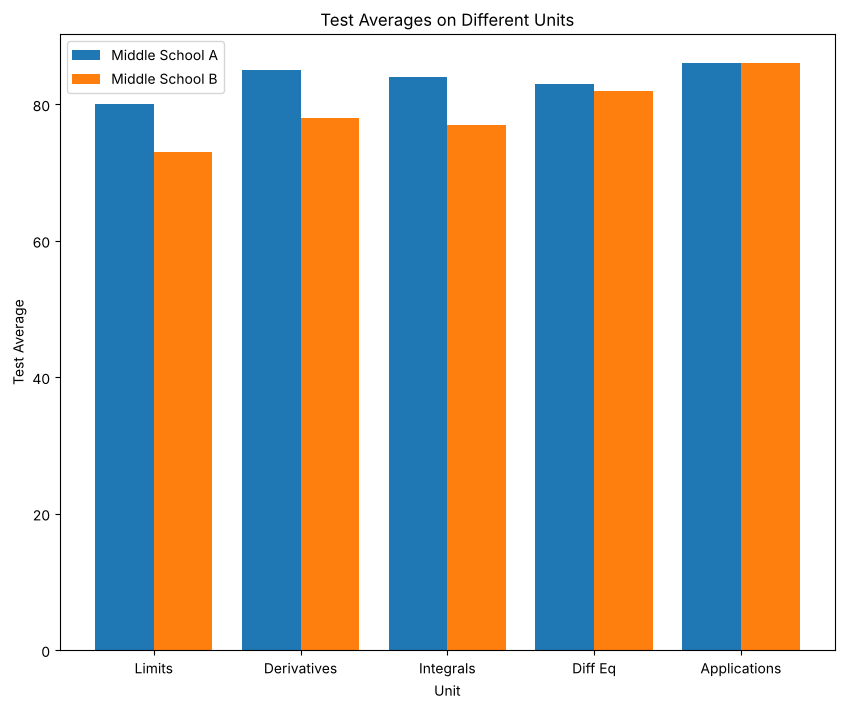

In [5]:
def create_x(t, w, n, d):
    return [t*x + w*n for x in range(d)]
# Make your chart here
#n = 1    # This is our first dataset (out of 2)
#t = 2    # Number of datasets
#d = 5    # Number of sets of bars
#w = 0.8  # Width of each bar
school_a_x = create_x(2,0.8,1,5)
school_b_x = create_x(2,0.8,2,5)

plt.figure(figsize=(10,8))

ax = plt.subplot()

ax.bar(school_a_x,middle_school_a)
ax.bar(school_b_x,middle_school_b)

middle_x = [(a+b)/2 for a,b in zip(school_a_x,school_b_x)]

ax.set_xticks(middle_x)
ax.set_xticklabels(unit_topics)

ax.legend(["Middle School A", "Middle School B"])

ax.set_title('Test Averages on Different Units')
ax.set_xlabel('Unit')
ax.set_ylabel("Test Average")

plt.savefig(CHARTS + 'recreate_02_side_by_side.png')
plt.show()

### `plt.` style vs `ax.` style
Here everything goes through `ax` - not only the ticks. That's how most professional code looks: every command says *which* chart it changes, which matters as soon as there are subplots. The only catch - some names differ:

| `plt.` style | `ax.` style |
|---|---|
| `plt.title()` | `ax.set_title()` |
| `plt.xlabel()` / `plt.ylabel()` | `ax.set_xlabel()` / `ax.set_ylabel()` |
| `plt.axis([...])` | `ax.set_xlim()` / `ax.set_ylim()` |
| `plt.bar()`, `plt.legend()` | `ax.bar()`, `ax.legend()` (same names) |

### `middle_x` with `zip`

```text
school_a_x:  0.8   2.8   4.8 ...
school_b_x:  1.6   3.6   5.6 ...
             \_/   \_/
middle_x:    1.2   3.2   5.2 ...   (a + b) / 2
```

Bars are centred on their x-values, so the midpoint lands exactly where each pair touches - where the label belongs. `zip` pairs the two lists element by element, like walking down two columns side by side (same trick as the three-layer stacked bars in [section 4 of the lesson](02_different_plot_types.ipynb)).

### Readability: name the arguments
`create_x(2,0.8,1,5)` works, but in six months nobody remembers which number is which. Name them - then the commented-out template isn't needed:

```python
school_a_x = create_x(t=2, w=0.8, n=1, d=5)
school_b_x = create_x(t=2, w=0.8, n=2, d=5)
```

Named arguments can go in any order and make the code explain itself - same as R's `create_x(t = 2, w = 0.8, ...)`.